# Lab 8 Edge Detection


In [ ]:
from pathlib import Path
import base64
import hashlib
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
names = ['Coins.png', 'Butterfly.jpg', 'bird.png', 'kid1.jpg']
folders = [Path.cwd(), Path.cwd() / 'outputs', Path.cwd().parent / 'outputs', Path.home() / 'Downloads']
asset_store = None
for folder in folders:
    for candidate in sorted(folder.glob('*.ipynb')):
        try:
            metadata = json.loads(candidate.read_text(encoding='utf-8')).get('metadata', {})
        except (OSError, UnicodeError, json.JSONDecodeError):
            continue
        stored = metadata.get('lab8_assets', {})
        if all(name in stored for name in names):
            asset_store = stored
            break
    if asset_store is not None:
        break
if asset_store is None:
    raise FileNotFoundError('Save this notebook in the Jupyter working directory, then run all cells again.')
images = {}
for name in names:
    raw = base64.b64decode(asset_store[name]['base64'], validate=True)
    assert hashlib.sha256(raw).hexdigest() == asset_store[name]['sha256']
    bgr = cv2.imdecode(np.frombuffer(raw, dtype=np.uint8), cv2.IMREAD_COLOR)
    assert bgr is not None
    images[name] = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    print(f'{name}: {images[name].shape[1]} x {images[name].shape[0]} pixels')

Coins.png: 468 x 326 pixels
Butterfly.jpg: 800 x 532 pixels
bird.png: 377 x 282 pixels
kid1.jpg: 525 x 350 pixels


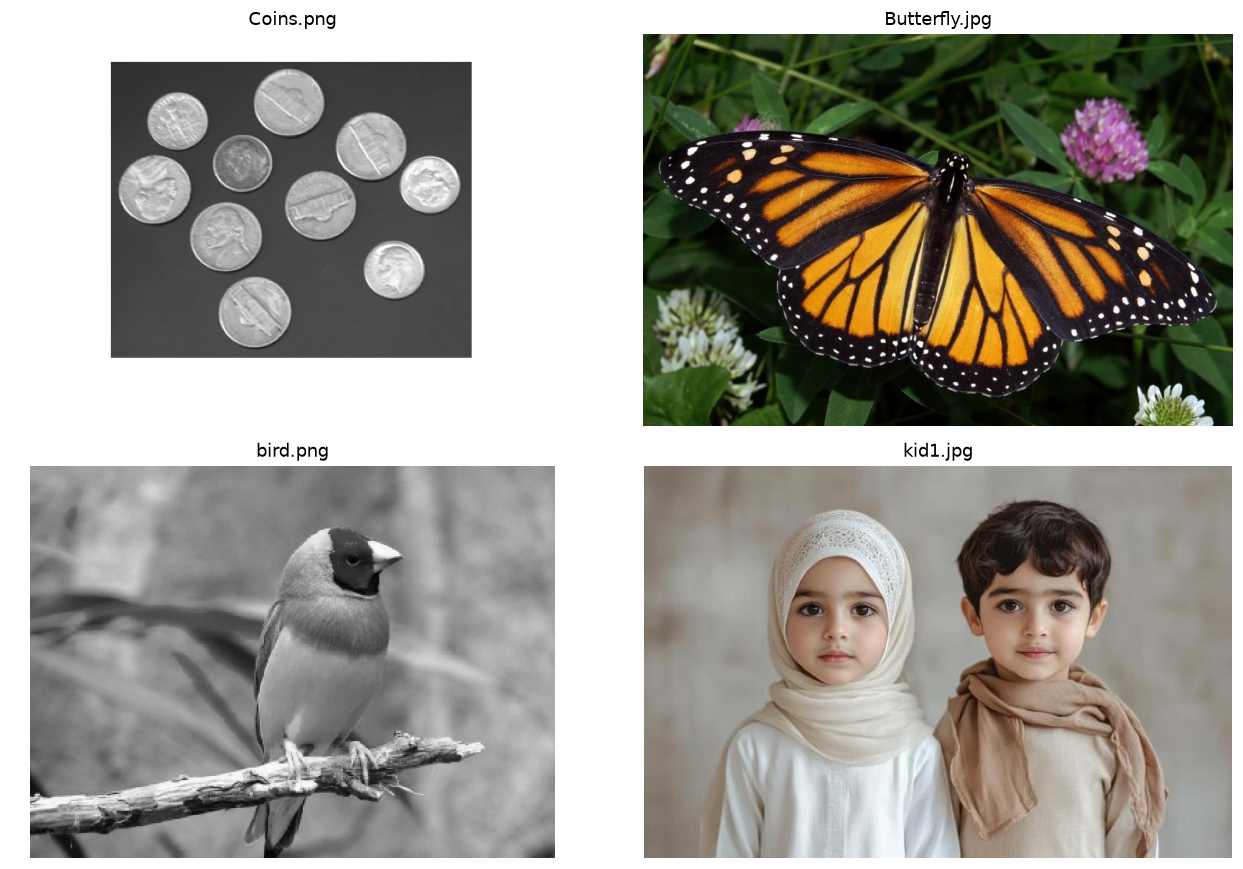

In [ ]:
def show_images(items, columns=2, size=(12, 8)):
    rows = (len(items) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=size, squeeze=False)
    for ax, (title, image) in zip(axes.flat, items):
        ax.imshow(image, cmap='gray' if image.ndim == 2 else None,
                  vmin=0 if image.ndim == 2 else None,
                  vmax=255 if image.ndim == 2 else None)
        ax.set_title(title)
        ax.axis('off')
    for ax in axes.flat[len(items):]:
        ax.axis('off')
    fig.tight_layout()
    plt.show()

def display_magnitude(response):
    magnitude = np.abs(response).astype(np.float64)
    maximum = float(magnitude.max())
    if maximum == 0:
        return np.zeros(magnitude.shape, dtype=np.uint8)
    return np.rint(magnitude * (255.0 / maximum)).astype(np.uint8)

def derivative_maps(gray):
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    sx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
    sy = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
    px = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
    py = px.T
    gx = cv2.filter2D(blurred, cv2.CV_64F, px)
    gy = cv2.filter2D(blurred, cv2.CV_64F, py)
    return blurred, display_magnitude(cv2.magnitude(sx, sy)), display_magnitude(cv2.magnitude(gx, gy))

show_images(list(images.items()), columns=2, size=(12, 8))

## Task 1 Apply Sobel, Prewitt and Canny


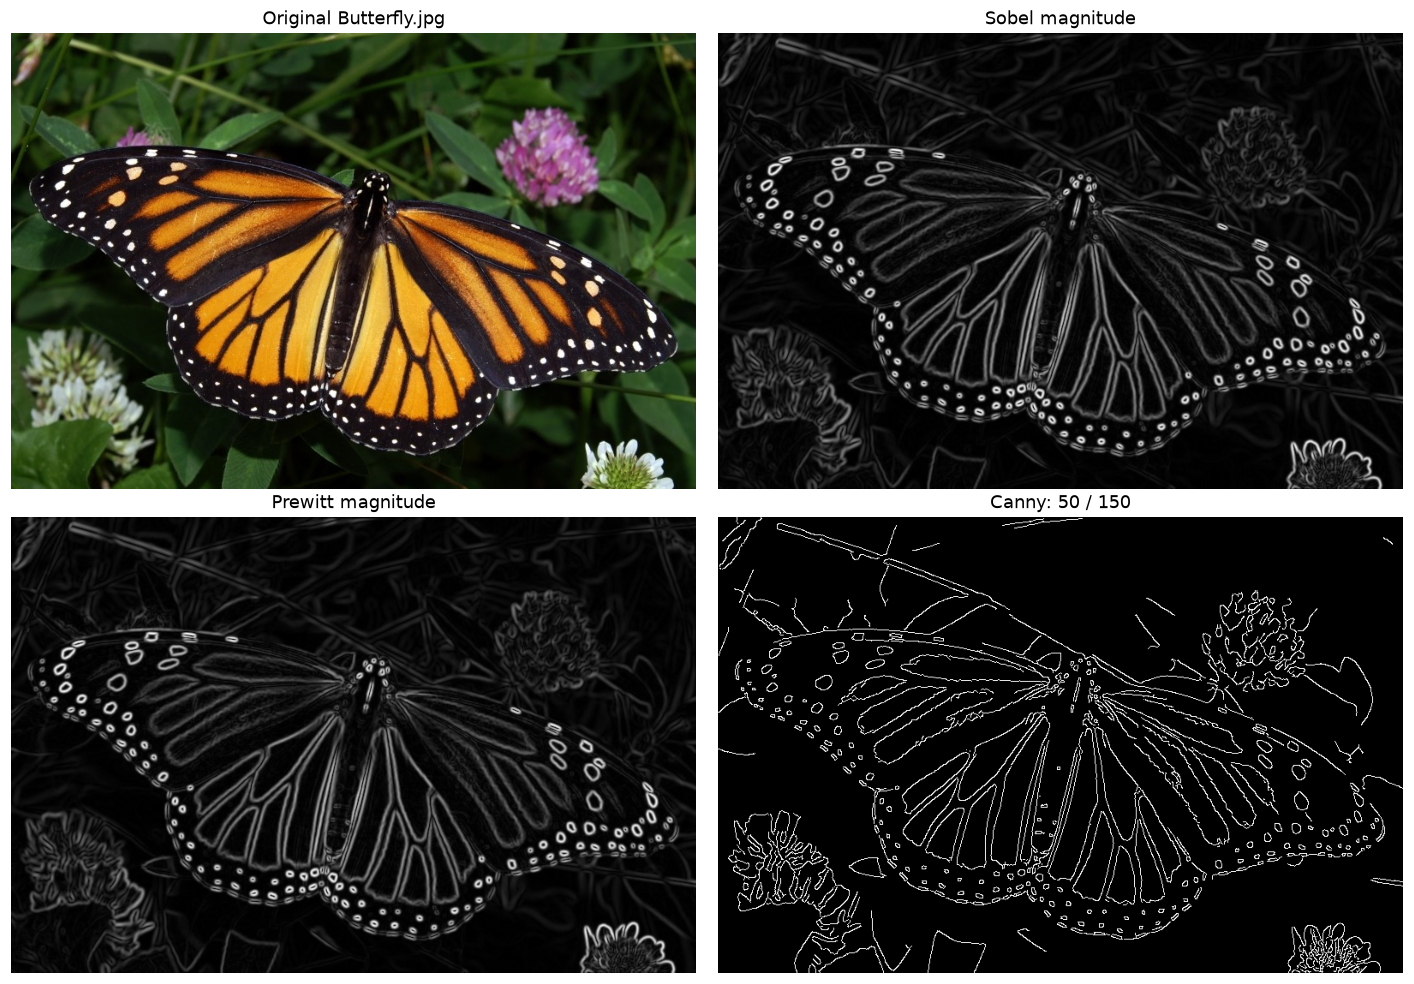

In [ ]:
selected_name = 'Butterfly.jpg'
selected = images[selected_name]
gray = cv2.cvtColor(selected, cv2.COLOR_RGB2GRAY)
blurred, sobel_edges, prewitt_edges = derivative_maps(gray)
canny_edges = cv2.Canny(blurred, 50, 150, apertureSize=3, L2gradient=False)
show_images([
    ('Original Butterfly.jpg', selected),
    ('Sobel magnitude', sobel_edges),
    ('Prewitt magnitude', prewitt_edges),
    ('Canny: 50 / 150', canny_edges)
], columns=2, size=(13, 9))

### Task 1 Comparison



## Task 2 Investigate the Canny Thresholds


Low= 30, high= 90: 33,792 edge pixels (7.94%)
Low= 50, high=150: 23,434 edge pixels (5.51%)
Low=100, high=200: 16,823 edge pixels (3.95%)


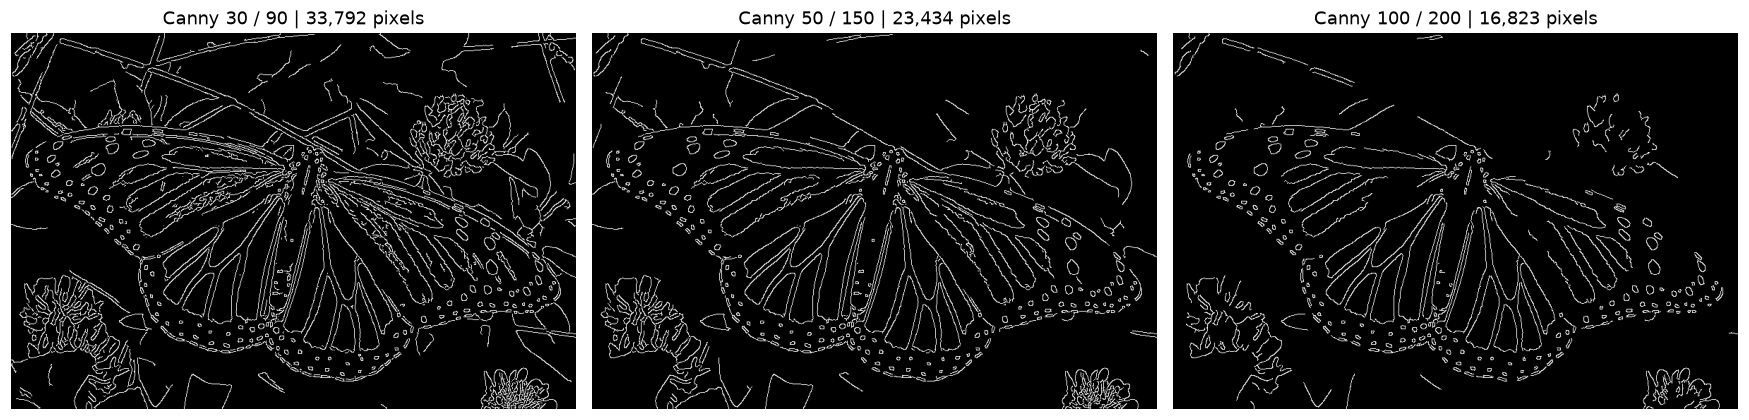

Raising thresholds from 30/90 to 100/200 removes 16,969 edge pixels.


In [ ]:
threshold_pairs = [(30, 90), (50, 150), (100, 200)]
threshold_edges = {}
counts = []
for low, high in threshold_pairs:
    edge_map = cv2.Canny(blurred, low, high, apertureSize=3, L2gradient=False)
    threshold_edges[(low, high)] = edge_map
    count = int(np.count_nonzero(edge_map))
    counts.append(count)
    print(f'Low={low:3d}, high={high:3d}: {count:,} edge pixels ({100 * count / edge_map.size:.2f}%)')
show_images([
    (f'Canny {low} / {high} | {count:,} pixels', threshold_edges[(low, high)])
    for (low, high), count in zip(threshold_pairs, counts)
], columns=3, size=(16, 5))
print(f'Raising thresholds from 30/90 to 100/200 removes {counts[0] - counts[-1]:,} edge pixels.')

### Task 2 Explanation

At **30 / 90**, more weak boundaries survive, exposing finer wing patterns as well as unwanted background texture. At **50 / 150**, fewer weak responses remain and the output balances detail and clutter. At **100 / 200**, strong wing contours remain prominent while some fine veins, low-contrast details and background edges disappear. The printed counts quantify this effect for the supplied butterfly image; they are edge-pixel counts, not the number of distinct objects or contours. Raising both thresholds with preprocessing fixed cannot add weak edge chains. The best choice depends on whether preserving fine details or suppressing clutter matters more.




### Roberts Cross and Smoothing Comparison


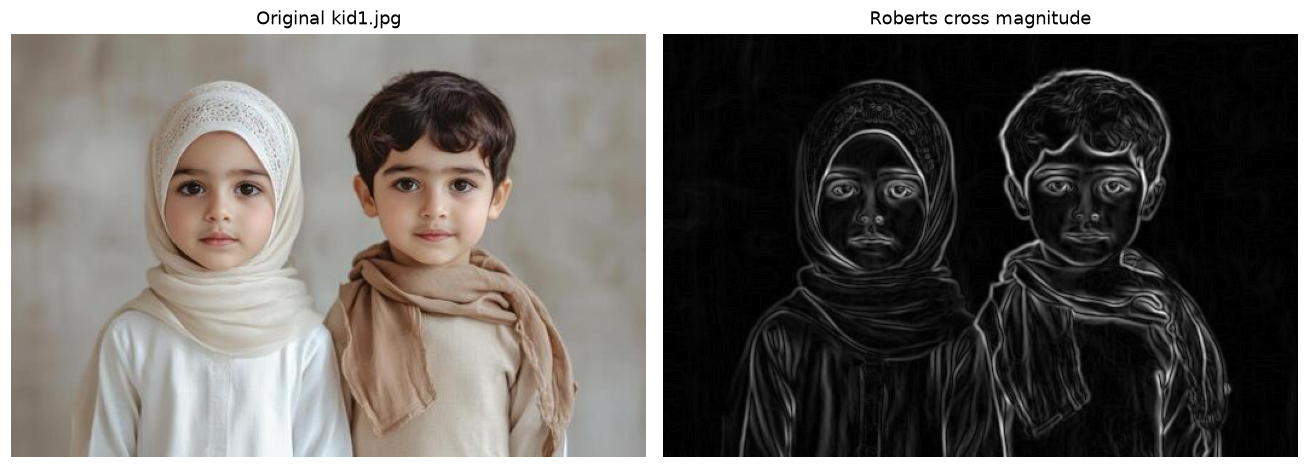

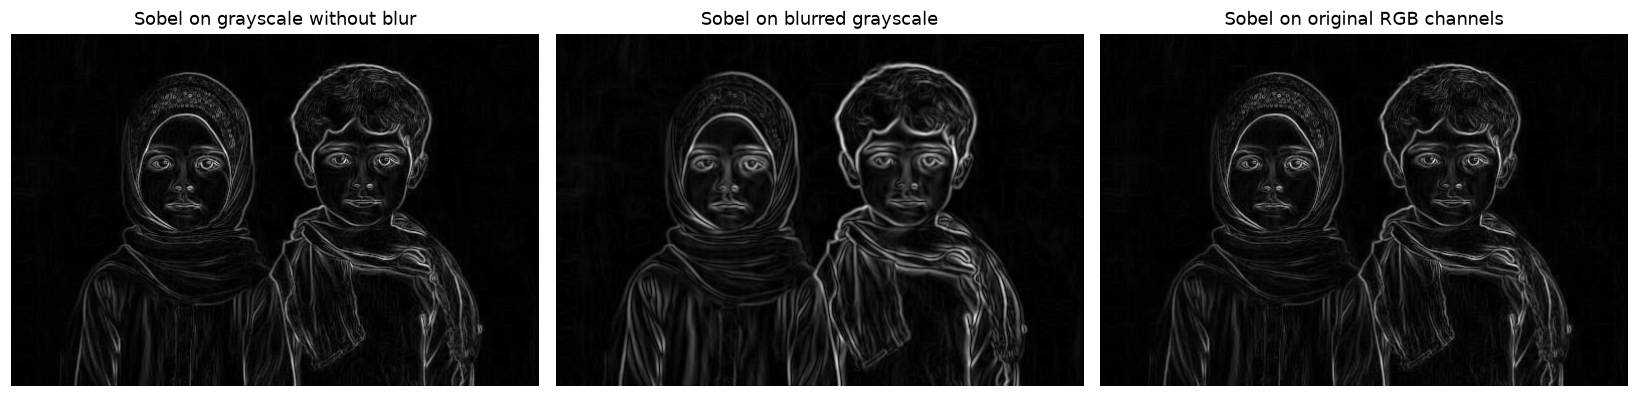

In [ ]:
kid = images['kid1.jpg']
kid_gray = cv2.cvtColor(kid, cv2.COLOR_RGB2GRAY)
kid_blurred = cv2.GaussianBlur(kid_gray, (5, 5), 0)
rx = np.array([[1, 0], [0, -1]], dtype=np.float64)
ry = np.array([[0, 1], [-1, 0]], dtype=np.float64)
roberts_x = cv2.filter2D(kid_blurred, cv2.CV_64F, rx)
roberts_y = cv2.filter2D(kid_blurred, cv2.CV_64F, ry)
roberts_edges = display_magnitude(cv2.magnitude(roberts_x, roberts_y))
show_images([('Original kid1.jpg', kid), ('Roberts cross magnitude', roberts_edges)], columns=2, size=(12, 5))

def sobel_magnitude(image):
    gx = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)
    energy = gx * gx + gy * gy
    return np.sqrt(energy.sum(axis=2) if image.ndim == 3 else energy)

show_images([
    ('Sobel on grayscale without blur', display_magnitude(sobel_magnitude(kid_gray))),
    ('Sobel on blurred grayscale', display_magnitude(sobel_magnitude(kid_blurred))),
    ('Sobel on original RGB channels', display_magnitude(sobel_magnitude(kid)))
], columns=3, size=(15, 4))

### Multichannel Canny and Color Gradient


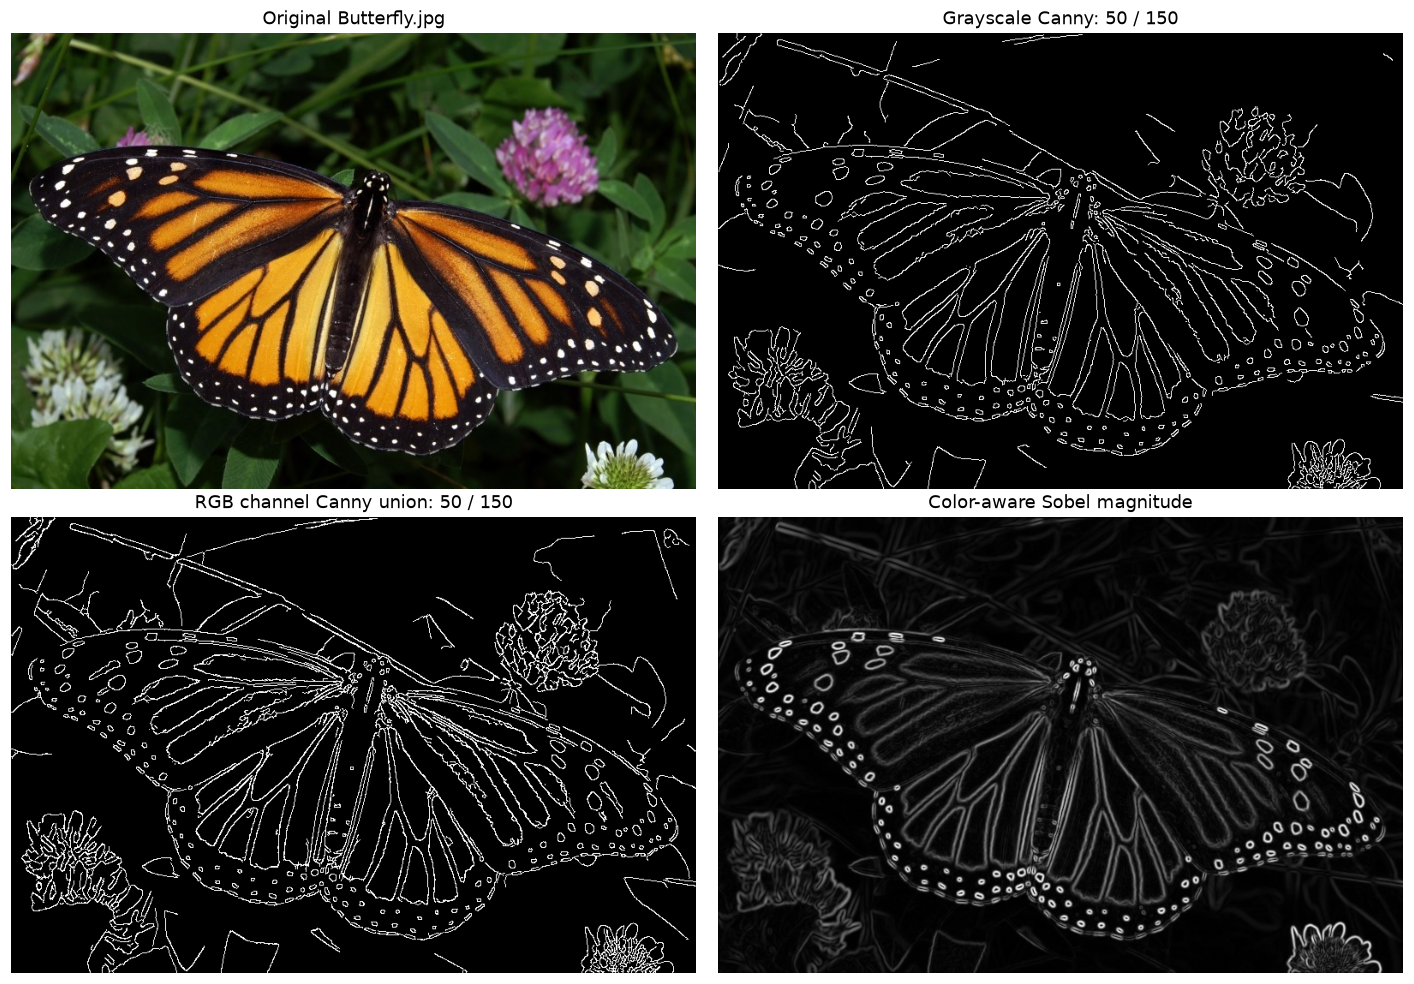

In [ ]:
def multichannel_canny(rgb, low=50, high=150):
    channel_edges = [cv2.Canny(cv2.GaussianBlur(channel, (5, 5), 0), low, high)
                     for channel in cv2.split(rgb)]
    return np.bitwise_or.reduce(channel_edges)

def color_gradient(rgb):
    smooth = cv2.GaussianBlur(rgb, (3, 3), 0)
    return display_magnitude(sobel_magnitude(smooth))

color_canny = multichannel_canny(selected)
color_edges = color_gradient(selected)
show_images([
    ('Original Butterfly.jpg', selected),
    ('Grayscale Canny: 50 / 150', canny_edges),
    ('RGB channel Canny union: 50 / 150', color_canny),
    ('Color-aware Sobel magnitude', color_edges)
], columns=2, size=(13, 9))

### Laplacian of Gaussian and Difference of Gaussians


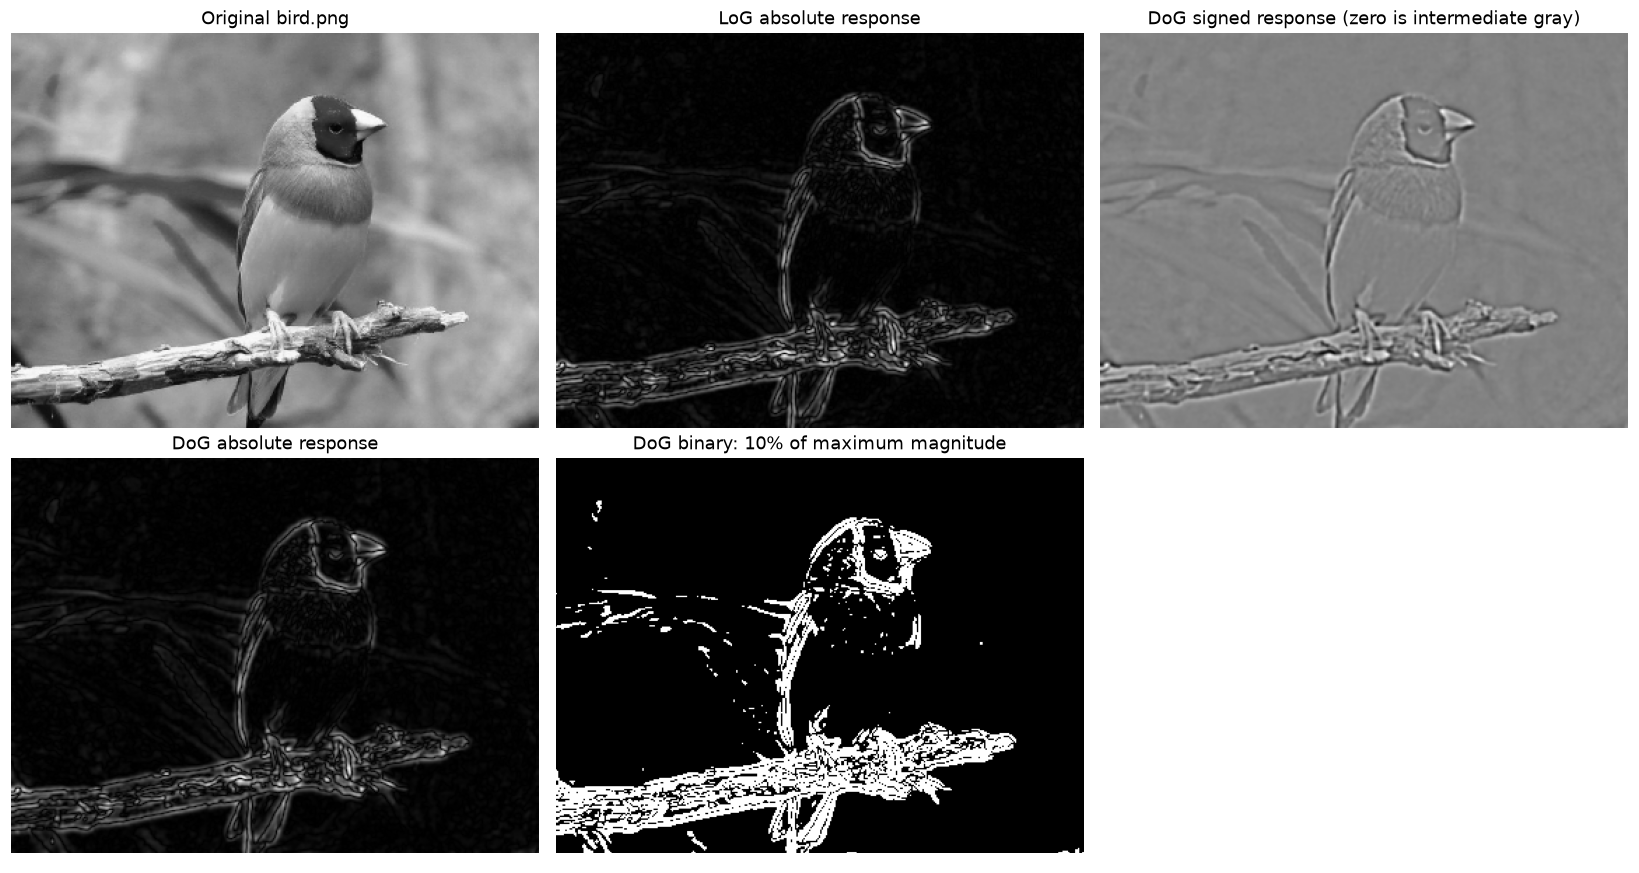

DoG magnitude threshold: 4.939 intensity units


In [ ]:
bird_gray = cv2.cvtColor(images['bird.png'], cv2.COLOR_RGB2GRAY)
bird_smooth = cv2.GaussianBlur(bird_gray, (5, 5), 0)
log_response = cv2.Laplacian(bird_smooth, cv2.CV_64F, ksize=5)
log_edges = display_magnitude(log_response)
bird_float = bird_gray.astype(np.float32)
dog_response = cv2.GaussianBlur(bird_float, (0, 0), 1.0) - cv2.GaussianBlur(bird_float, (0, 0), 2.0)
dog_signed_display = cv2.normalize(dog_response, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
dog_magnitude = display_magnitude(dog_response)
dog_threshold = 0.10 * float(np.abs(dog_response).max())
dog_binary = (np.abs(dog_response) > dog_threshold).astype(np.uint8) * 255
show_images([
    ('Original bird.png', images['bird.png']),
    ('LoG absolute response', log_edges),
    ('DoG signed response (zero is intermediate gray)', dog_signed_display),
    ('DoG absolute response', dog_magnitude),
    ('DoG binary: 10% of maximum magnitude', dog_binary)
], columns=3, size=(15, 8))
print(f'DoG magnitude threshold: {dog_threshold:.3f} intensity units')

### All Eight Detectors on Coins

The full **Coins.png** image is retained, including its white surrounding border. That frame is a real intensity boundary and therefore appears in the edge maps. This comparison does not count or segment coins. LoG and DoG are displayed as absolute magnitudes; Canny results are binary.

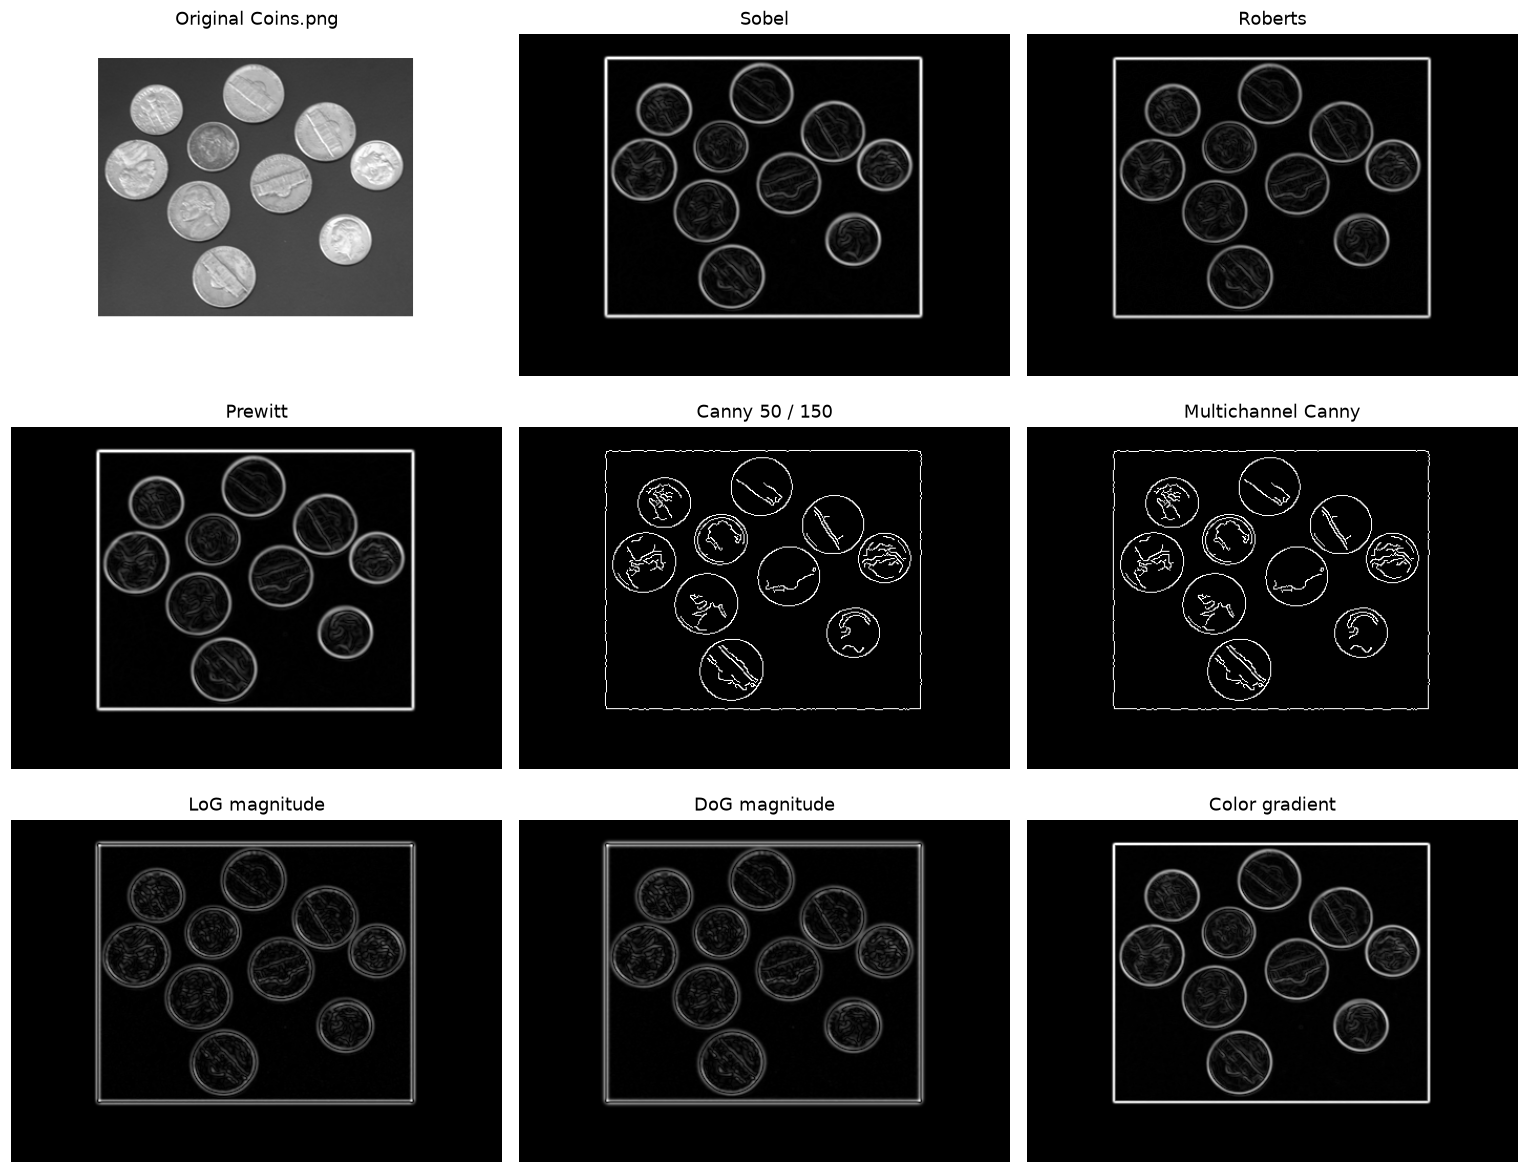

In [ ]:
coins = images['Coins.png']
coins_gray = cv2.cvtColor(coins, cv2.COLOR_RGB2GRAY)
coins_blurred, coins_sobel, coins_prewitt = derivative_maps(coins_gray)
coins_roberts = display_magnitude(cv2.magnitude(
    cv2.filter2D(coins_blurred, cv2.CV_64F, rx),
    cv2.filter2D(coins_blurred, cv2.CV_64F, ry)))
coins_float = coins_gray.astype(np.float32)
coins_dog = cv2.GaussianBlur(coins_float, (0, 0), 1.0) - cv2.GaussianBlur(coins_float, (0, 0), 2.0)
coins_results = {
    'Sobel': coins_sobel,
    'Roberts': coins_roberts,
    'Prewitt': coins_prewitt,
    'Canny 50 / 150': cv2.Canny(coins_blurred, 50, 150),
    'Multichannel Canny': multichannel_canny(coins),
    'LoG magnitude': display_magnitude(cv2.Laplacian(coins_blurred, cv2.CV_64F, ksize=5)),
    'DoG magnitude': display_magnitude(coins_dog),
    'Color gradient': color_gradient(coins)
}
show_images([('Original Coins.png', coins)] + list(coins_results.items()), columns=3, size=(14, 11))

## Verification and Conclusions

The final checks validate image integrity, output shapes and types, finite values, the binary range of Canny, monotonic threshold behavior, and safe handling of constant images. Exact edge counts depend on OpenCV implementation details; the saved outputs report the results of this execution.

Sobel and Prewitt are useful for continuous gradient strength, Roberts uses small diagonal differences, and Canny provides thin binary edges with explicit threshold control. LoG and DoG expose changes across spatial scales. The color methods retain per-channel information. The butterfly comparison demonstrates how increasing Canny thresholds removes weak details together with background texture. No ground-truth edge annotations were supplied, so visual quality and edge counts are not claimed as detection accuracy.

In [ ]:
assert selected_name != 'kid1.jpg'
assert len(images) == 4
for name, image in images.items():
    assert image.dtype == np.uint8 and image.ndim == 3 and image.shape[2] == 3
    assert np.isfinite(image).all()
for result in [sobel_edges, prewitt_edges, canny_edges, color_canny, color_edges]:
    assert result.shape == gray.shape and result.dtype == np.uint8
for result in list(threshold_edges.values()) + [color_canny, dog_binary]:
    assert set(np.unique(result)).issubset({0, 255})
for earlier, later in zip(threshold_pairs, threshold_pairs[1:]):
    assert np.all((threshold_edges[later] == 0) | (threshold_edges[earlier] != 0))
assert counts[0] >= counts[1] >= counts[2] > 0
for result in coins_results.values():
    assert result.shape == coins_gray.shape and result.dtype == np.uint8
assert np.isfinite(log_response).all() and np.isfinite(dog_response).all()
assert log_response.min() < 0 < log_response.max()
assert dog_response.min() < 0 < dog_response.max()
constant = np.full((32, 32), 128, dtype=np.uint8)
constant_blur, constant_sobel, constant_prewitt = derivative_maps(constant)
assert not np.any(constant_sobel) and not np.any(constant_prewitt)
assert not np.any(cv2.Canny(constant_blur, 30, 90))
assert not np.any(display_magnitude(np.zeros((8, 8))))
print('All image integrity, detector, threshold and numerical checks passed.')
print(f'OpenCV {cv2.__version__}; NumPy {np.__version__}')

All image integrity, detector, threshold and numerical checks passed.
OpenCV 5.0.0; NumPy 2.5.4
